In [1]:
import rasterio 
from rasterio.windows import from_bounds


## Load the region of interest around La Burtignière

1. Choose 2 points that delineate your area of interest (LV95)
    Bottom-Left: 2501690.17,1155001.27
    Top-Right: 2503639.05, 1158009.32
2. Convert the points to LV03

In [25]:
from rasterio.warp import transform_bounds

lon_min = 2501690.17
lat_min = 1155001.27
lon_max = 2503639.05
lat_max = 1158009.32


left, bottom, right, top = transform_bounds(
    "EPSG:2056", "EPSG:21781",
    lon_min, lat_min, lon_max, lat_max
)

In [26]:
print(right,top)


503639.04999999993 158009.3200000039


In [27]:
from rasterio.windows import Window

with rasterio.open("/home/tleona/Documents/burtigniere/gis/catchment_analysis/DHM25_MM_ASCII_GRID/ASCII_GRID_1part/dhm25_grid_raster.asc") as src:
    window = from_bounds(left,bottom,right,top,transform=src.transform)
    window = window.round_offsets().round_lengths()

    dem = src.read(1, window = window)
    transform = src.window_transform(window) # needed to set the top-right corner the pixel (0,0)

    profile = src.profile.copy()
    profile.update(height = dem.shape[0], width = dem.shape[1],transform = transform)

cell_width, cell_height = src.res
cell_area_m2_2 = cell_height*cell_height

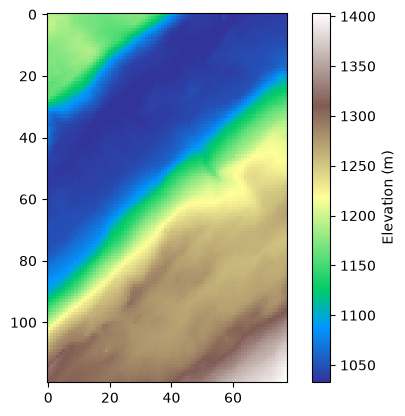

In [ ]:
import matplotlib.pyplot as plt

plt.imshow(dem, cmap = 'terrain')
plt.colorbar(label="Elevation (m)")

## Now save the cropped DEM as a GeoTIFF file

In [29]:
from pathlib import Path

project_root = Path.cwd()

profile = src.profile.copy()

profile.update(
    driver = "GTiff",
    height = dem.shape[0],
    width = dem.shape[1],
    transform = transform,
    crs = "EPSG:21781",
    compress = "deflate",
    tiles = True
)

with rasterio.open(project_root.parent/"data"/"dhm25_crop_burti.tif","w",**profile) as dst:
    dst.write(dem,1)

ERROR 10: Pointer 'hObject' is NULL in 'GDALGetMetadata'.

ERROR 10: Pointer 'hObject' is NULL in 'GDALGetMetadata'.

ERROR 10: Pointer 'hObject' is NULL in 'GDALGetMetadata'.

